# Baseline Benchmark: Binary Classification (`is_cancer`)

Establishes a binary (`is_cancer`: `0` vs. `1`) reference benchmark using **Random Forest** and **Logistic Regression** on the preprocessed tabular split so multiclass (`diagnostic`, `01_*`–`04_*`) performance on the same cohort can be directly compared.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    log_loss,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:


SEED = 42
SAVE_PLOTS = True
DATA_DIR = Path("../Dataset/processed/a01_A_impute_simple")
OUT_DIR = Path("../Output/binary_benchmark")

if SAVE_PLOTS:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Saving outputs to: {OUT_DIR.resolve()}")

Saving outputs to: C:\Users\Administrator\Desktop\skin-project\Output\binary_benchmark


In [3]:
with open(DATA_DIR / "feature_columns.json", "r", encoding="utf-8") as f:
    config = json.load(f)

features = config["features"]
target = "is_cancer"


train_df = pd.read_csv(DATA_DIR / "final_train.csv")
test_df = pd.read_csv(DATA_DIR / "final_test.csv")

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape:     {X_test.shape}")

Training set shape: (1838, 24)
Test set shape:     (460, 24)


In [4]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=SEED,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec_w = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec_w = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_w = f1_score(y_test, y_pred, average="weighted", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
logloss = log_loss(y_test, y_prob)
conf_matrix = confusion_matrix(y_test, y_pred)

print("=" * 50)
print("1. RANDOM FOREST — HOLD-OUT TEST SET EVALUATION")
print("=" * 50)
print(f"Accuracy:       {acc:.4f}")
print(f"Weighted Prec:  {prec_w:.4f}")
print(f"Weighted Rec:   {rec_w:.4f}")
print(f"Weighted F1:    {f1_w:.4f}")
print(f"Macro F1:       {f1_macro:.4f}")
print(f"ROC-AUC Score:  {roc_auc:.4f}")
print(f"Log Loss:       {logloss:.4f}\n")
print("Confusion Matrix (rows=true, cols=pred):")
print(conf_matrix)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

1. RANDOM FOREST — HOLD-OUT TEST SET EVALUATION
Accuracy:       0.8261
Weighted Prec:  0.8261
Weighted Rec:   0.8261
Weighted F1:    0.8261
Macro F1:       0.8259
ROC-AUC Score:  0.9051
Log Loss:       0.7565

Confusion Matrix (rows=true, cols=pred):
[[198  39]
 [ 41 182]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8285    0.8354    0.8319       237
           1     0.8235    0.8161    0.8198       223

    accuracy                         0.8261       460
   macro avg     0.8260    0.8258    0.8259       460
weighted avg     0.8261    0.8261    0.8261       460



In [5]:
X_all = pd.concat([X_train, X_test], axis=0)
y_all = pd.concat([y_train, y_test], axis=0)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_accuracies = cross_val_score(rf_model, X_all, y_all, cv=cv, scoring="accuracy")
cv_f1 = cross_val_score(rf_model, X_all, y_all, cv=cv, scoring="f1_weighted")
cv_roc_auc = cross_val_score(rf_model, X_all, y_all, cv=cv, scoring="roc_auc")

print("=" * 50)
print("2. RANDOM FOREST — 5-FOLD STRATIFIED CV")
print("=" * 50)
print(f"5-Fold CV Accuracies: {np.round(cv_accuracies, 4)}")
print(f"Mean CV Accuracy:     {cv_accuracies.mean():.4f} (±{cv_accuracies.std():.4f})")
print(f"Mean CV F1-Score:     {cv_f1.mean():.4f} (±{cv_f1.std():.4f})")
print(f"Mean CV ROC-AUC:      {cv_roc_auc.mean():.4f} (±{cv_roc_auc.std():.4f})")

2. RANDOM FOREST — 5-FOLD STRATIFIED CV
5-Fold CV Accuracies: [0.8435 0.8543 0.8739 0.8758 0.8671]
Mean CV Accuracy:     0.8629 (±0.0123)
Mean CV F1-Score:     0.8630 (±0.0123)
Mean CV ROC-AUC:      0.9259 (±0.0104)


Saved figure to: ..\Output\binary_benchmark\rf_binary_benchmark_eval.png


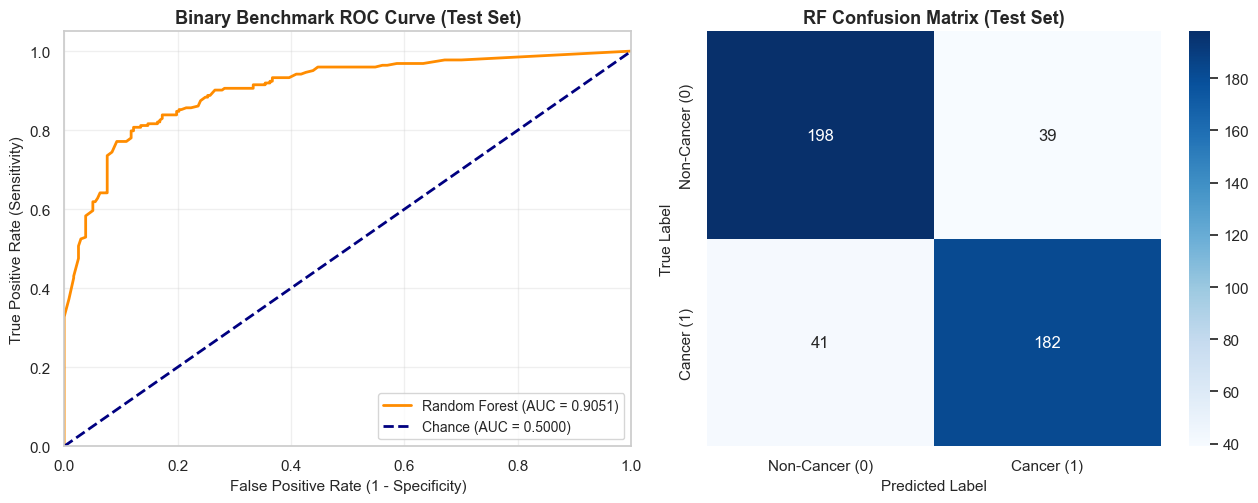

In [6]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

axes[0].plot(fpr, tpr, color="darkorange", lw=2, label=f"Random Forest (AUC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Chance (AUC = 0.5000)")
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)

axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
axes[0].set_title("Binary Benchmark ROC Curve (Test Set)", fontsize=13, fontweight="bold")
axes[0].legend(loc="lower right", fontsize=10)
axes[0].grid(alpha=0.3)

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Cancer (0)", "Cancer (1)"],
    yticklabels=["Non-Cancer (0)", "Cancer (1)"],
    ax=axes[1],
)
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].set_ylabel("True Label", fontsize=11)
axes[1].set_title("RF Confusion Matrix (Test Set)", fontsize=13, fontweight="bold")

plt.tight_layout()
if SAVE_PLOTS:
    fig_path = OUT_DIR / "rf_binary_benchmark_eval.png"
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    print(f"Saved figure to: {fig_path}")
plt.show()

In [7]:
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
lr_pipe.fit(X_train, y_train)

lr_preds = lr_pipe.predict(X_test)
lr_probs = lr_pipe.predict_proba(X_test)[:, 1]

lr_acc = accuracy_score(y_test, lr_preds)
lr_f1_macro = f1_score(y_test, lr_preds, average="macro", zero_division=0)
lr_auc = roc_auc_score(y_test, lr_probs)
lr_cm = confusion_matrix(y_test, lr_preds)

print("=" * 50)
print("3. LOGISTIC REGRESSION — HOLD-OUT TEST SET EVALUATION")
print("=" * 50)
print(f"Accuracy:       {lr_acc:.4f}")
print(f"Macro F1:       {lr_f1_macro:.4f}")
print(f"ROC-AUC Score:  {lr_auc:.4f}\n")
print("Confusion Matrix (rows=true, cols=pred):")
print(lr_cm)
print("\nClassification Report:")
print(classification_report(y_test, lr_preds, digits=4))

if SAVE_PLOTS:
    summary_df = pd.DataFrame([
        {"model": "Random Forest", "accuracy": acc, "macro_f1": f1_macro, "weighted_f1": f1_w, "roc_auc": roc_auc},
        {"model": "Logistic Regression", "accuracy": lr_acc, "macro_f1": lr_f1_macro, "weighted_f1": f1_score(y_test, lr_preds, average='weighted'), "roc_auc": lr_auc},
    ])
    summary_df.to_csv(OUT_DIR / "binary_benchmark_summary.csv", index=False)
    print(f"Saved summary table to: {OUT_DIR / 'binary_benchmark_summary.csv'}")

3. LOGISTIC REGRESSION — HOLD-OUT TEST SET EVALUATION
Accuracy:       0.8587
Macro F1:       0.8586
ROC-AUC Score:  0.9331

Confusion Matrix (rows=true, cols=pred):
[[203  34]
 [ 31 192]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8675    0.8565    0.8620       237
           1     0.8496    0.8610    0.8552       223

    accuracy                         0.8587       460
   macro avg     0.8585    0.8588    0.8586       460
weighted avg     0.8588    0.8587    0.8587       460

Saved summary table to: ..\Output\binary_benchmark\binary_benchmark_summary.csv
